<a href="https://colab.research.google.com/github/AlbertP97/Med-VQA-Survey/blob/main/VQA_MED_2019.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Med VQA 2019 Dataset Analysis

This notebook analyzes the Med VQA 2019 dataset for the doctoral research project (Paper 2).
The analysis follows the same structure used in the VQA-RAD notebook.

## 1. Import Libraries

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from nltk.tokenize import word_tokenize

# Download the required NLTK data
nltk.download('punkt', quiet=True)

# Visualization configuration
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 2. Data Loading

In [2]:
from google.colab import files
import json
import pandas as pd

# Select and load the file from the computer
uploaded_files = files.upload()

# Get the uploaded file name
file_name = next(iter(uploaded_files))

# Read the JSON file
json_data = json.loads(uploaded_files[file_name].decode('utf-8'))

# Convert it to a DataFrame
df = pd.DataFrame(json_data)

Saving Med VQA 2019.json to Med VQA 2019.json


In [3]:
df

,image_name,question,answer,split,img_id
0,synpic41148,what kind of image is this?,cta - ct angiography,train,41148
1,synpic43984,is this a t1 weighted image?,no,train,43984
2,synpic38930,what type of imaging modality is used to acqui...,us - ultrasound,train,38930
3,synpic52143,is this a noncontrast mri?,no,train,52143
4,synpic20934,what type of image modality is this?,xr - plain film,train,20934
...,...,...,...,...,...
15287,abnormality,what is abnormal in the ct scan?,ossification of stylohyoid ligament,test,
15288,abnormality,what is most alarming about this mri?,cerebral infarct,test,
15289,abnormality,what is most alarming about this ct scan?,epiploic appendagitis,test,
15290,abnormality,what is the primary abnormality in this image?,pancreatic ductal adenocarcinoma,test,


In [4]:
print("Dataset loaded successfully")
print(f"Number of records: {len(df)}")
print(f"Number of columns: {len(df.columns)}")
print("Available columns:")
print(df.columns.tolist())

Dataset loaded successfully
Number of records: 15292
Number of columns: 5
Available columns:
['image_name', 'question', 'answer', 'split', 'img_id']


In [5]:
# Define the list of allowed variables
variables = [
    'image_name',
    'question',
    'answer',
    'img_id'
 ]

print("Allowed variables in Med VQA 2019:")
for variable in variables:
    print(f"  - {variable}")

Allowed variables in Med VQA 2019:
  - image_name
  - question
  - answer
  - img_id


In [6]:
import nltk
nltk.download('punkt_tab')
# Calculate question and answer lengths (characters)
df['question_length'] = df['question'].str.len()
df['answer_length'] = df['answer'].str.len()

def count_words_nltk(text: str) -> int:
    """Count words in a text using NLTK, excluding spaces.

    Args:
        text: The text to analyze.

    Returns:
        The number of words excluding spaces.
    """
    if not isinstance(text, str) or not text.strip():
        return 0
    tokens = word_tokenize(text.lower())
    words = [token for token in tokens if token.strip()]
    return len(words)

df['question_words'] = df['question'].apply(count_words_nltk)
df['answer_words'] = df['answer'].apply(count_words_nltk)

print("Length columns created successfully")
print("  - question_length (characters)")
print("  - answer_length (characters)")
print("  - question_words (words)")
print("  - answer_words (words)")

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Length columns created successfully
  - question_length (characters)
  - answer_length (characters)
  - question_words (words)
  - answer_words (words)


In [7]:
# Test images do not follow the 'synpicXXXXX' pattern, so they are counted individually
synpic_pattern = df['image_name'].str.match(r'^synpic\d+$')
unique_images = df.loc[synpic_pattern, 'image_name'].nunique() + (~synpic_pattern).sum()

#unique_images = df['image_name'].nunique()

print(f"Number of unique images: {unique_images}")

Number of unique images: 4200


## 3. Exploratory Data Analysis

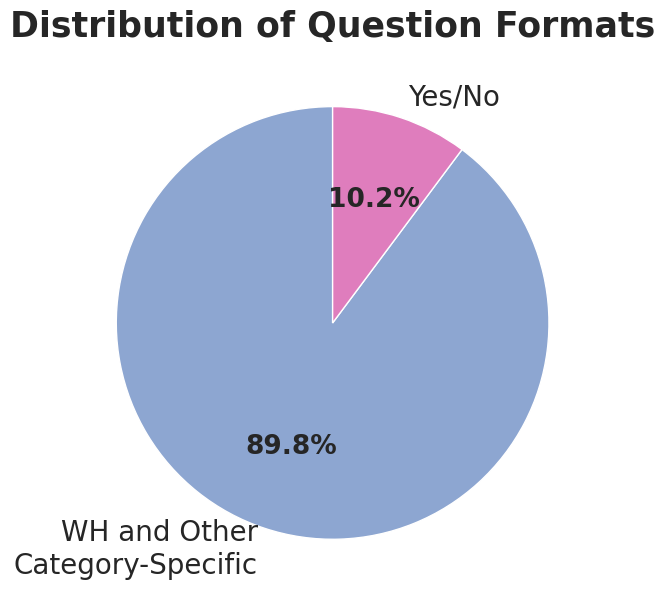

In [8]:
# ============================================================
# DISTRIBUTION OF QUESTION FORMATS
# ============================================================

import matplotlib.pyplot as plt

# Normalize the answers
answers = (
    df['answer']
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Separate questions according to the answer format:
# yes/no versus WH and other category-specific questions
df['question_format'] = answers.apply(
    lambda answer: 'Yes/No'
    if answer in ['yes', 'no']
    else 'WH and Other Category-Specific'
)

# Calculate frequencies in a fixed order
format_order = [
    'WH and Other Category-Specific',
    'Yes/No'
]

format_counts = (
    df['question_format']
    .value_counts()
    .reindex(format_order, fill_value=0)
)

# Create the figure
fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, percentages = ax.pie(
    format_counts.values,
    labels=[
        'WH and Other\nCategory-Specific',
        'Yes/No'
    ],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#8DA6D1', '#DF7DBD'],
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1
    },
    textprops={
        'fontsize': 20
    }
)

# Percentage formatting
for percentage in percentages:
    percentage.set_fontsize(19)
    percentage.set_fontweight('bold')

ax.set_title(
    'Distribution of Question Formats',
    fontsize=25,
    fontweight='bold',
    pad=35
)

ax.axis('equal')

plt.tight_layout()
plt.show()

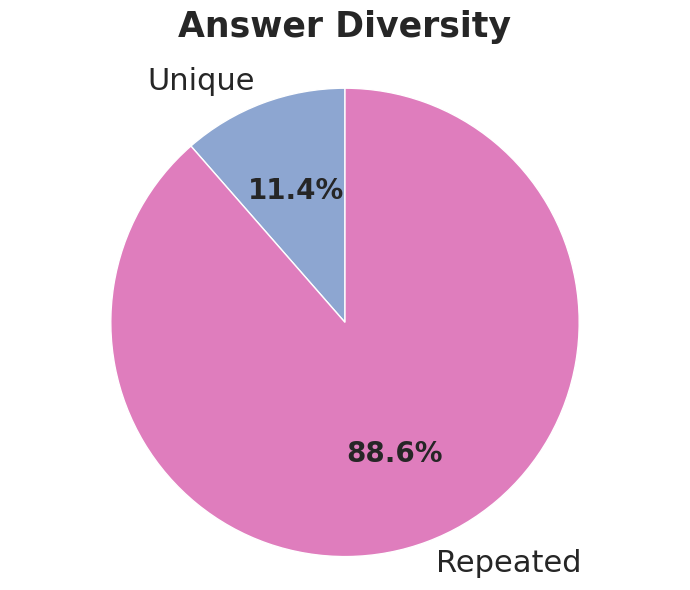

In [9]:
# ============================================================
# FIGURE 1: NORMALIZED ANSWER DIVERSITY
# ============================================================

# Detect the answer column name
if 'answer' in df.columns:
    answer_column = 'answer'
elif 'Answer' in df.columns:
    answer_column = 'Answer'
else:
    raise KeyError(
        f"The answer column was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Normalize the answers
normalized_answers = (
    df[answer_column]
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty answers
normalized_answers = normalized_answers[
    normalized_answers != ''
]

# Calculate counts
total_answers = len(normalized_answers)
unique_answers = normalized_answers.nunique()
repeated_answers = total_answers - unique_answers

# Create the figure
fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, percentages = ax.pie(
    [unique_answers, repeated_answers],
    labels=['Unique', 'Repeated'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#8DA6D1', '#DF7DBD'],
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1
    },
    textprops={
        'fontsize': 22
    }
)

# Format percentages only
for percentage in percentages:
    percentage.set_fontsize(20)
    percentage.set_fontweight('bold')

ax.set_title(
    f'Answer Diversity',

    fontsize=25,
    fontweight='bold',
    pad=20
)

ax.axis('equal')

plt.tight_layout()
plt.show()

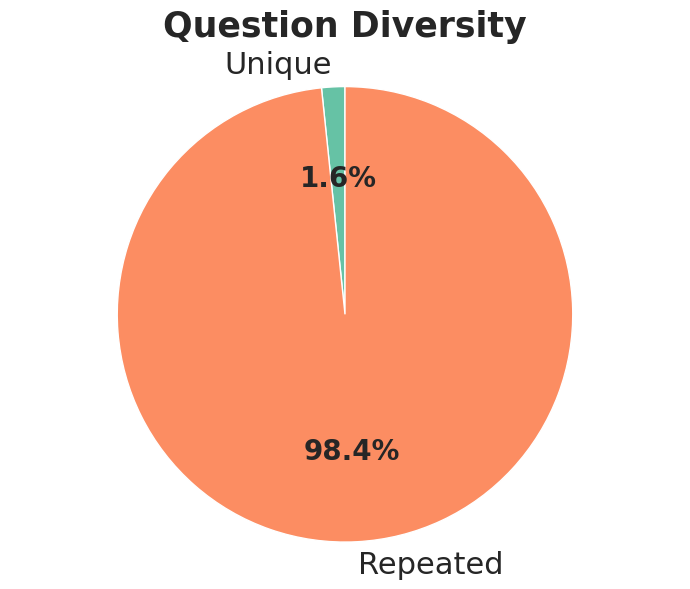

In [10]:
# ============================================================
# FIGURE 2: NORMALIZED QUESTION DIVERSITY
# ============================================================

# Detect the question column name
if 'question' in df.columns:
    question_column = 'question'
elif 'Question' in df.columns:
    question_column = 'Question'
else:
    raise KeyError(
        f"The question column was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Normalize the questions
normalized_questions = (
    df[question_column]
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty questions
normalized_questions = normalized_questions[
    normalized_questions != ''
]

# Calculate counts
total_questions = len(normalized_questions)
unique_questions = normalized_questions.nunique()
repeated_questions = total_questions - unique_questions

# Create the figure
fig, ax = plt.subplots(figsize=(7, 6))

wedges, texts, percentages = ax.pie(
    [unique_questions, repeated_questions],
    labels=['Unique', 'Repeated'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#66C2A5', '#FC8D62'],
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1
    },
    textprops={
        'fontsize': 22
    }
)

# Format percentages only
for percentage in percentages:
    percentage.set_fontsize(20)
    percentage.set_fontweight('bold')

ax.set_title(
    f'Question Diversity',

    fontsize=25,
    fontweight='bold',
    pad=20
)

ax.axis('equal')

plt.tight_layout()
plt.show()

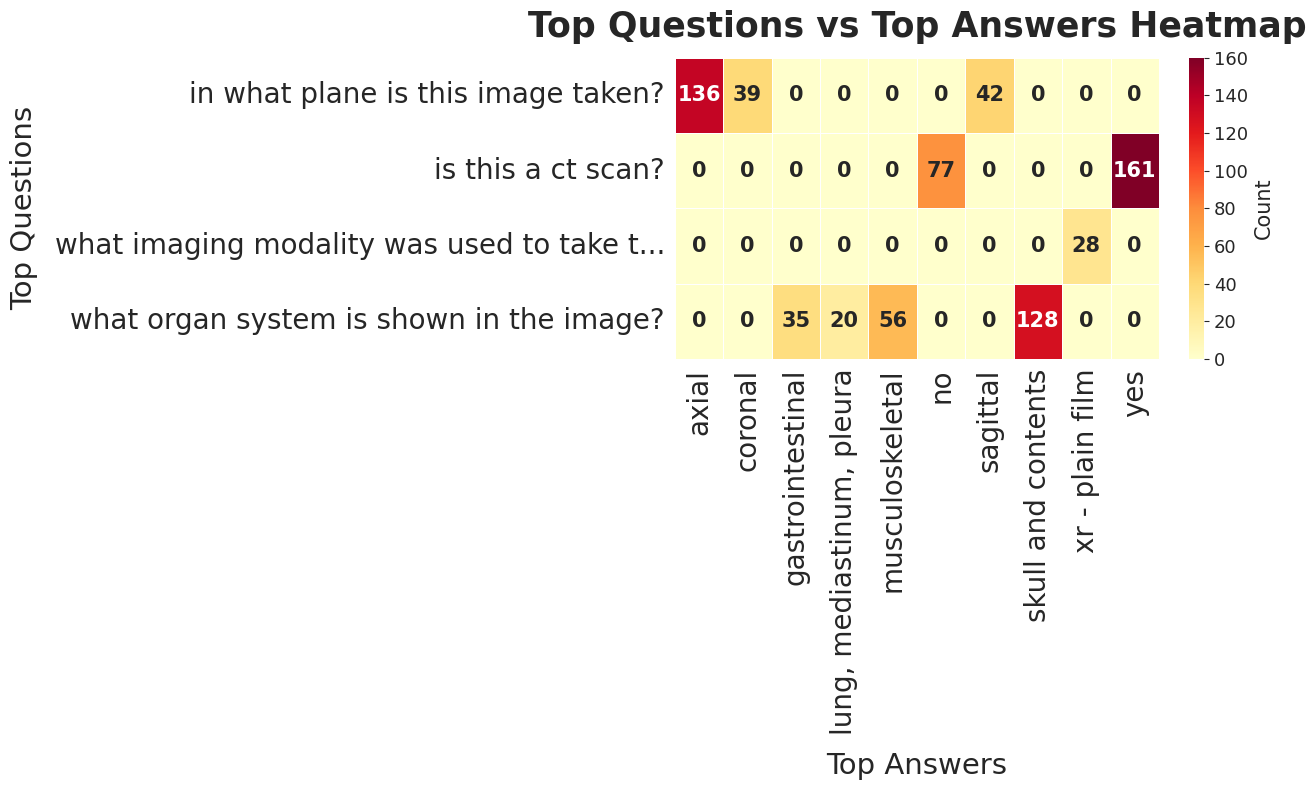

In [11]:
# ============================================================
# FIGURE 3: TOP QUESTIONS VS TOP ANSWERS HEATMAP
# ============================================================

# Detect columns
if 'question' in df.columns:
    question_column = 'question'
elif 'Question' in df.columns:
    question_column = 'Question'
else:
    raise KeyError("The question column was not found.")

if 'answer' in df.columns:
    answer_column = 'answer'
elif 'Answer' in df.columns:
    answer_column = 'Answer'
else:
    raise KeyError("The answer column was not found.")

# Normalize questions and answers
df_heatmap = pd.DataFrame({
    'Question': (
        df[question_column]
        .fillna('')
        .astype(str)
        .str.lower()
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    ),
    'Answer': (
        df[answer_column]
        .fillna('')
        .astype(str)
        .str.lower()
        .str.strip()
        .str.replace(r'\s+', ' ', regex=True)
    )
})

# Questions used in the original figure
selected_questions = [
    'in what plane is this image taken?',
    'is this a ct scan?',
    'what imaging modality was used to take this image?',
    'what organ system is shown in the image?'
]

# Answers used in the original figure
selected_answers = [
    'axial',
    'coronal',
    'gastrointestinal',
    'lung, mediastinum, pleura',
    'musculoskeletal',
    'no',
    'sagittal',
    'skull and contents',
    'xr - plain film',
    'yes'
]

# Create frequency table
heatmap_table = pd.crosstab(
    df_heatmap['Question'],
    df_heatmap['Answer']
)

# Select and order the questions and answers
heatmap_table = heatmap_table.reindex(
    index=selected_questions,
    columns=selected_answers,
    fill_value=0
)

# Abbreviated question labels
question_labels = [
    'in what plane is this image taken?',
    'is this a ct scan?',
    'what imaging modality was used to take t...',
    'what organ system is shown in the image?'
]

# Create figure
fig, ax = plt.subplots(figsize=(13, 8))

sns.heatmap(
    heatmap_table,
    annot=True,
    fmt='d',
    cmap='YlOrRd',
    linewidths=0.7,
    linecolor='white',
    vmin=0,
    vmax=160,
    cbar_kws={'label': 'Count'},
    annot_kws={
        'fontsize': 15,
        'fontweight': 'bold'
    },
    ax=ax
)

ax.set_title(
    'Top Questions vs Top Answers Heatmap',
    fontsize=25,
    fontweight='bold',
    pad=15
)

ax.set_xlabel(
    'Top Answers',
    fontsize=21,
    labelpad=12
)

ax.set_ylabel(
    'Top Questions',
    fontsize=21,
    labelpad=12
)

ax.set_xticklabels(
    selected_answers,
    rotation=90,
    fontsize=20
)

ax.set_yticklabels(
    question_labels,
    rotation=0,
    fontsize=20
)

# Configure color bar
colorbar = ax.collections[0].colorbar
colorbar.ax.tick_params(labelsize=13)
colorbar.set_label(
    'Count',
    fontsize=15
)

plt.tight_layout()
plt.show()

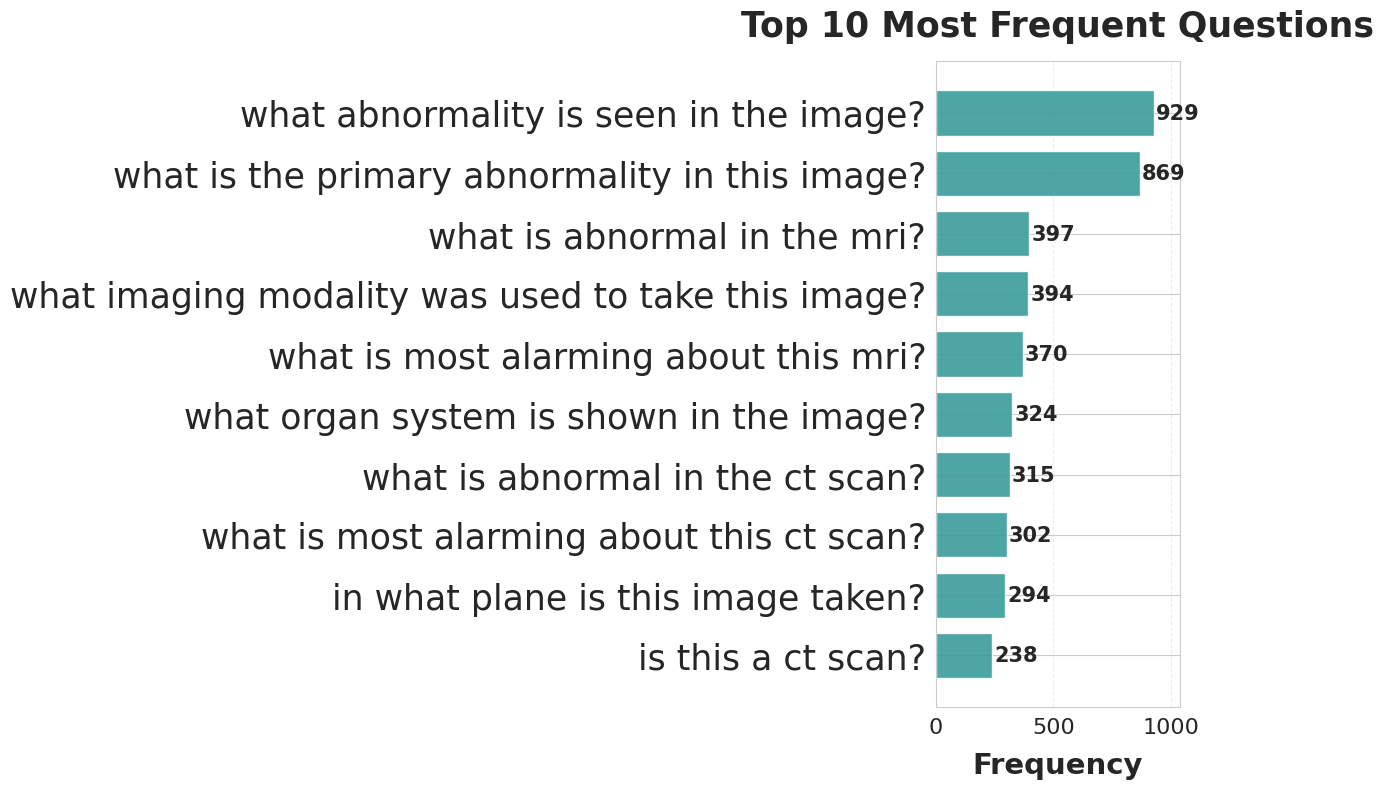

In [12]:
# ============================================================
# FIGURE 4: TOP 20 MOST FREQUENT QUESTIONS
# ============================================================

# Detect the question column
if 'question' in df.columns:
    question_column = 'question'
elif 'Question' in df.columns:
    question_column = 'Question'
else:
    raise KeyError(
        f"The question column was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Normalize the questions
normalized_questions = (
    df[question_column]
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty questions
normalized_questions = normalized_questions[
    normalized_questions != ''
]

# Get the 20 most frequent questions
top_questions = (
    normalized_questions
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# Abbreviate only questions that are too long
labels = [
    question if len(question) <= 65
    else question[:62] + '...'
    for question in top_questions.index
]

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

# Control the spacing between bars
# A smaller number places the bars closer together
positions = np.arange(len(top_questions)) * 0.60

bars = ax.barh(
    positions,
    top_questions.values,
    color='#3A9D9A',
    height=0.45,  # Bar thickness
    alpha=0.9
)

# Place the questions on the vertical axis
ax.set_yticks(positions)

ax.set_yticklabels(
    labels,
    fontsize=25
)

# Display the value at the end of each bar
offset = max(top_questions.values) * 0.01

for bar, value in zip(bars, top_questions.values):
    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f'{value}',
        va='center',
        ha='left',
        fontsize=15,
        fontweight='bold'
    )

ax.set_title(
    'Top 10 Most Frequent Questions',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel('')

ax.tick_params(
    axis='x',
    labelsize=16
)

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.35
)

# Leave space so the numbers are visible
ax.set_xlim(
    0,
    max(top_questions.values) * 1.12
)

plt.tight_layout()
plt.show()

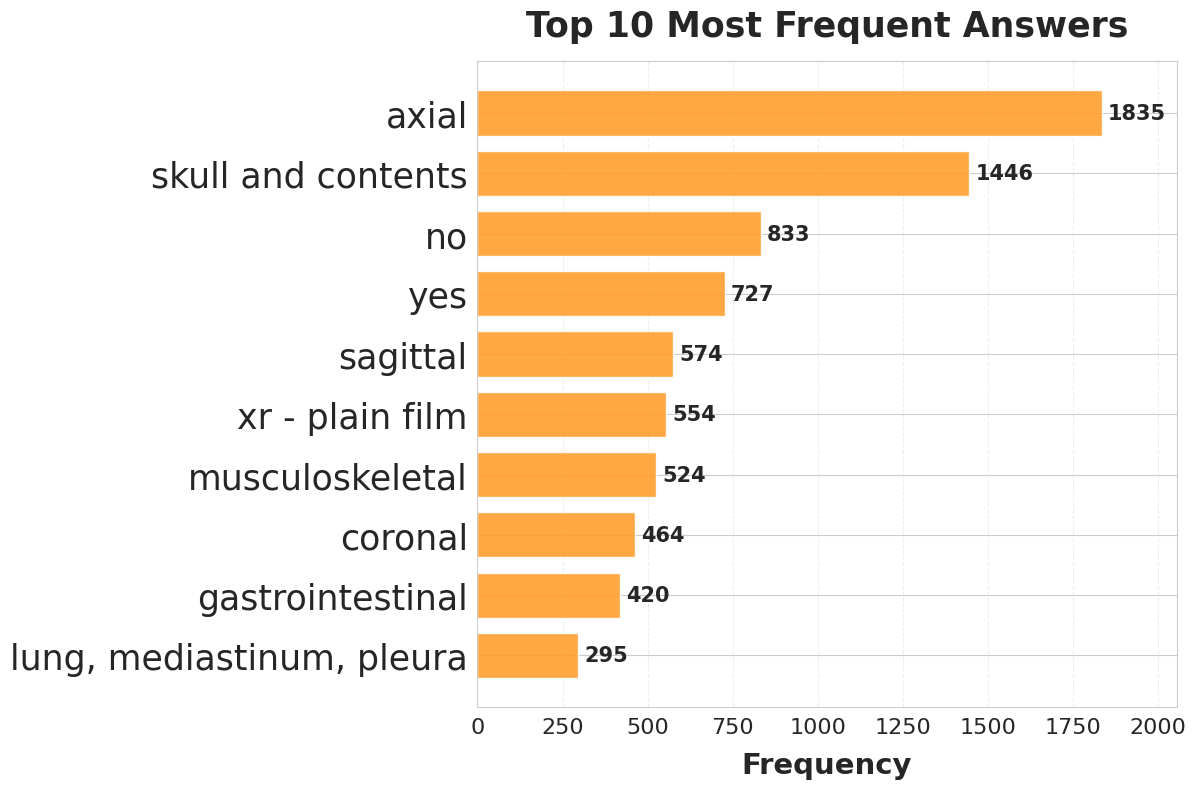

In [13]:
# ============================================================
# FIGURE 5: TOP 10 MOST FREQUENT ANSWERS
# ============================================================

# Detect the answer column
if 'answer' in df.columns:
    answer_column = 'answer'
elif 'Answer' in df.columns:
    answer_column = 'Answer'
else:
    raise KeyError(
        f"The answer column was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Normalize the answers
normalized_answers = (
    df[answer_column]
    .fillna('')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

# Remove empty answers
normalized_answers = normalized_answers[
    normalized_answers != ''
]

# Get the 10 most frequent answers
top_answers = (
    normalized_answers
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

# Abbreviate answers that are too long
answer_labels = [
    answer if len(answer) <= 65
    else answer[:62] + '...'
    for answer in top_answers.index
]

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

# Control the spacing between bars
positions = np.arange(len(top_answers)) * 0.60

bars = ax.barh(
    positions,
    top_answers.values,
    color='#FF9F2F',
    height=0.45,
    alpha=0.9
)

# Place the answers on the vertical axis
ax.set_yticks(positions)

ax.set_yticklabels(
    answer_labels,
    fontsize=25
)

# Display the value at the end of each bar
offset = max(top_answers.values) * 0.01

for bar, value in zip(bars, top_answers.values):
    ax.text(
        value + offset,
        bar.get_y() + bar.get_height() / 2,
        f'{value}',
        va='center',
        ha='left',
        fontsize=15,
        fontweight='bold'
    )

ax.set_title(
    'Top 10 Most Frequent Answers',
    fontsize=25,
    fontweight='bold',
    pad=18
)

ax.set_xlabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=10
)

ax.set_ylabel('')

ax.tick_params(
    axis='x',
    labelsize=16
)

ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.35
)

# Leave space so the numbers are visible
ax.set_xlim(
    0,
    max(top_answers.values) * 1.12
)

plt.tight_layout()
plt.show()

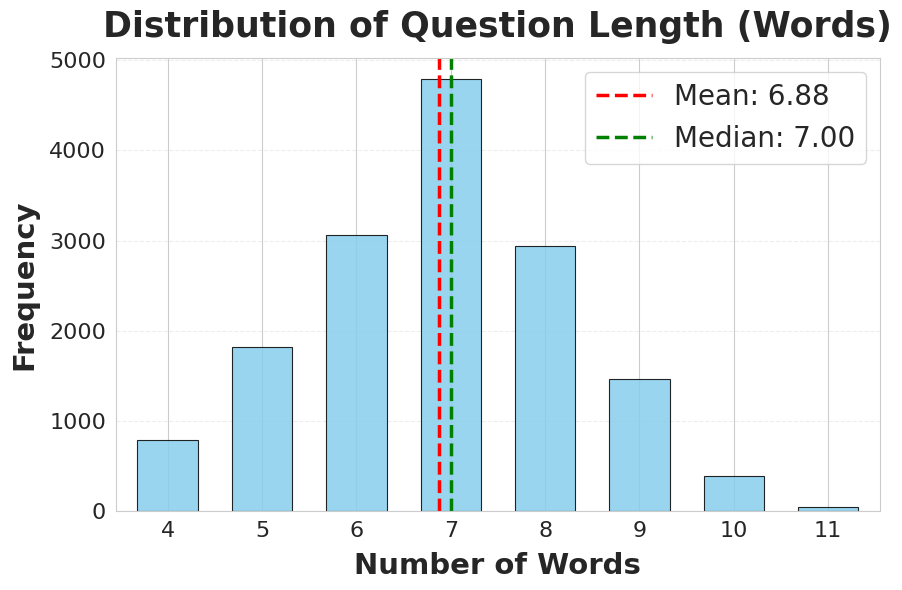

In [14]:
# ============================================================
# FIGURE 6: DISTRIBUTION OF QUESTION LENGTH
# Compact version for the paper
# ============================================================

# Detect the question column
if 'question' in df.columns:
    question_column = 'question'
elif 'Question' in df.columns:
    question_column = 'Question'
else:
    raise KeyError(
        f"The question column was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Prepare the questions
questions = (
    df[question_column]
    .fillna('')
    .astype(str)
    .str.strip()
)

questions = questions[questions != '']

# Calculate the number of words
question_lengths = questions.str.split().str.len()

# Calculate the mean and median
mean = question_lengths.mean()
median = question_lengths.median()

# Calculate frequencies for each length
frequencies = (
    question_lengths
    .value_counts()
    .sort_index()
)

# Closely spaced bar positions
positions = np.arange(len(frequencies)) * 0.50

# Convert the mean and median to plot positions
mean_position = np.interp(
    mean,
    frequencies.index.to_numpy(),
    positions
)

median_position = np.interp(
    median,
    frequencies.index.to_numpy(),
    positions
)

# Create figure compacta
fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    positions,
    frequencies.values,
    width=0.32,
    color='#87CEEB',
    edgecolor='black',
    linewidth=0.8,
    alpha=0.85
)

# Mean line
ax.axvline(
    mean_position,
    color='red',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {mean:.2f}'
)

# Mean linena
ax.axvline(
    median_position,
    color='green',
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {median:.2f}'
)

ax.set_title(
    'Distribution of Question Length (Words)',
    fontsize=25,
    fontweight='bold',
    pad=15
)

ax.set_xlabel(
    'Number of Words',
    fontsize=21,
    fontweight='bold',
    labelpad=8
)

ax.set_ylabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=8
)

# X-axis labels
ax.set_xticks(positions)

ax.set_xticklabels(
    frequencies.index,
    fontsize=16
)

ax.tick_params(
    axis='y',
    labelsize=16
)

ax.legend(
    fontsize=20,
    loc='upper right',
    frameon=True
)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.35
)

ax.margins(x=0.03)

plt.tight_layout()
plt.show()

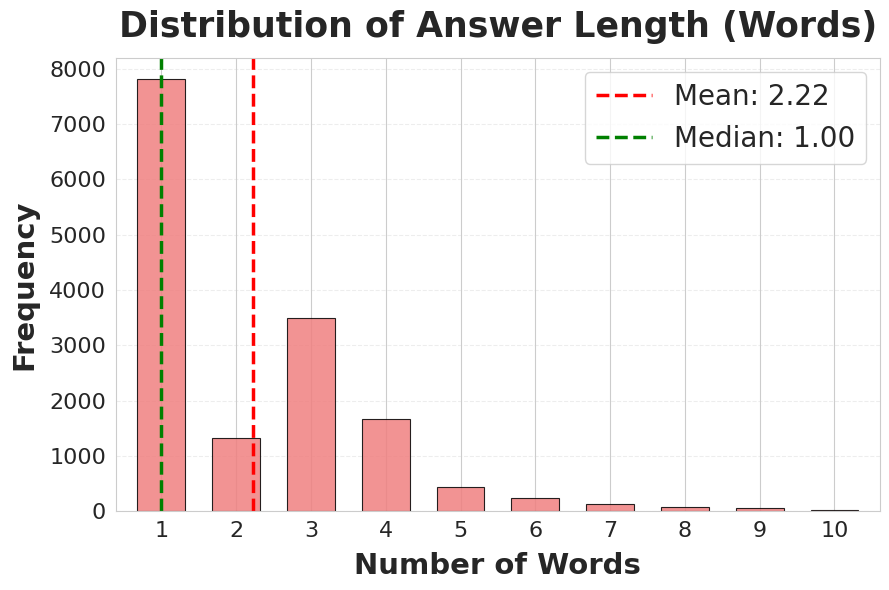

In [15]:
# ============================================================
# FIGURE 7: DISTRIBUTION OF ANSWER LENGTH
# Compact version for the paper
# ============================================================

# Detect the answer column
if 'answer' in df.columns:
    answer_column = 'answer'
elif 'Answer' in df.columns:
    answer_column = 'Answer'
else:
    raise KeyError(
        f"The answer column was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

# Prepare the answers
answers = (
    df[answer_column]
    .fillna('')
    .astype(str)
    .str.strip()
)

answers = answers[answers != '']

# Calculate the number of words
answer_lengths = answers.str.split().str.len()

# Show only lengths from 1 to 10 words
answer_lengths = answer_lengths[
    (answer_lengths >= 1) &
    (answer_lengths <= 10)
]

# Calculate the mean and median using all original answers
mean = answers.str.split().str.len().mean()
median = answers.str.split().str.len().median()

# Calculate frequencies from 1 to 10 words
frequencies = (
    answer_lengths
    .value_counts()
    .reindex(range(1, 11), fill_value=0)
)

# Closely spaced bar positions
positions = np.arange(len(frequencies)) * 0.50

# Convert the mean and median to plot positions
mean_position = np.interp(
    mean,
    frequencies.index.to_numpy(),
    positions
)

median_position = np.interp(
    median,
    frequencies.index.to_numpy(),
    positions
)

# Create figure compacta
fig, ax = plt.subplots(figsize=(9, 6))

ax.bar(
    positions,
    frequencies.values,
    width=0.32,
    color='#F08080',
    edgecolor='black',
    linewidth=0.8,
    alpha=0.85
)

# Mean line
ax.axvline(
    mean_position,
    color='red',
    linestyle='--',
    linewidth=2.5,
    label=f'Mean: {mean:.2f}'
)

# Mean linena
ax.axvline(
    median_position,
    color='green',
    linestyle='--',
    linewidth=2.5,
    label=f'Median: {median:.2f}'
)

ax.set_title(
    'Distribution of Answer Length (Words)',
    fontsize=25,
    fontweight='bold',
    pad=15
)

ax.set_xlabel(
    'Number of Words',
    fontsize=21,
    fontweight='bold',
    labelpad=8
)

ax.set_ylabel(
    'Frequency',
    fontsize=21,
    fontweight='bold',
    labelpad=8
)

# X-axis labels
ax.set_xticks(positions)

ax.set_xticklabels(
    frequencies.index,
    fontsize=16
)

ax.tick_params(
    axis='y',
    labelsize=16
)

ax.legend(
    fontsize=20,
    loc='upper right',
    frameon=True
)

ax.grid(
    axis='y',
    linestyle='--',
    alpha=0.35
)

ax.margins(x=0.03)

plt.tight_layout()
plt.show()